In [1]:

# Step 3.20 - Final Test Evaluation: Logistic Regression

import pandas as pd
import joblib
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Find project directory
project_path = Path.cwd()

if project_path.name == "notebooks":
    project_path = project_path.parent

# 2. Load untouched test dataset
test_df = pd.read_csv(
    project_path / "data" / "test.csv"
)

print("Test samples:", len(test_df))

# 3. Load saved Logistic Regression model
lr_model = joblib.load(
    project_path / "models" / "logistic_regression_model.pkl"
)

# 4. Load saved TF-IDF vectorizer
tfidf = joblib.load(
    project_path / "models" / "tfidf_vectorizer.pkl"
)

print("Logistic Regression model loaded successfully!")

# 5. Prepare test features and labels
X_test = test_df["text"].fillna("").astype(str)
y_test = test_df["sentiment"]

# 6. Transform test reviews
# IMPORTANT: Do not fit the vectorizer again
X_test_tfidf = tfidf.transform(X_test)

# 7. Predict sentiment
lr_test_predictions = lr_model.predict(X_test_tfidf)

# 8. Calculate final test metrics
lr_test_accuracy = accuracy_score(
    y_test, lr_test_predictions
)

lr_test_precision = precision_score(
    y_test, lr_test_predictions,
    average="macro", zero_division=0
)

lr_test_recall = recall_score(
    y_test, lr_test_predictions,
    average="macro", zero_division=0
)

lr_test_f1 = f1_score(
    y_test, lr_test_predictions,
    average="macro", zero_division=0
)

# 9. Display results
print("\nLogistic Regression - Final Test Results")
print("----------------------------------------")

print(f"Accuracy: {lr_test_accuracy:.4f}")
print(f"Macro Precision: {lr_test_precision:.4f}")
print(f"Macro Recall: {lr_test_recall:.4f}")
print(f"Macro F1: {lr_test_f1:.4f}")

# 10. Classification report
print("\nClassification Report:")

print(classification_report(
    y_test,
    lr_test_predictions,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

# 11. Confusion matrix
lr_test_cm = confusion_matrix(
    y_test,
    lr_test_predictions,
    labels=[0, 1, 2]
)

print("\nConfusion Matrix:")
print(lr_test_cm)

print("\nStep 3.20 completed successfully!")


Test samples: 743
Logistic Regression model loaded successfully!

Logistic Regression - Final Test Results
----------------------------------------
Accuracy: 0.7483
Macro Precision: 0.5497
Macro Recall: 0.5917
Macro F1: 0.5652

Classification Report:
              precision    recall  f1-score   support

    Negative       0.49      0.59      0.54        95
     Neutral       0.25      0.36      0.30        75
    Positive       0.91      0.83      0.86       573

    accuracy                           0.75       743
   macro avg       0.55      0.59      0.57       743
weighted avg       0.79      0.75      0.77       743


Confusion Matrix:
[[ 56  19  20]
 [ 20  27  28]
 [ 38  62 473]]

Step 3.20 completed successfully!


In [2]:

# Step 3.21 - Final DistilBERT Test Evaluation

import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# 2. Load selected DistilBERT model
model_path = (
    project_path / "models" / "distilbert_full_epoch2"
)

print("\nLoading fine-tuned DistilBERT...")

tokenizer = AutoTokenizer.from_pretrained(model_path)

distilbert_model = (
    AutoModelForSequenceClassification.from_pretrained(
        model_path
    )
)

distilbert_model = distilbert_model.to(device)
distilbert_model.eval()

# 3. Define test dataset class
class DistilBERTTestDataset(Dataset):

    def __init__(self, texts, labels, tokenizer):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):

        encoding = self.tokenizer(
            str(self.texts[index]),
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                int(self.labels[index]),
                dtype=torch.long
            )
        }

# 4. Prepare the same test reviews
distilbert_test_dataset = DistilBERTTestDataset(
    texts=test_df["text"],
    labels=test_df["sentiment"],
    tokenizer=tokenizer
)

test_loader = DataLoader(
    distilbert_test_dataset,
    batch_size=8,
    shuffle=False
)

# 5. Generate predictions
bert_predictions = []
bert_labels = []

print("\nEvaluating DistilBERT on test dataset...")

with torch.no_grad():

    for batch in test_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        outputs = distilbert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        bert_predictions.extend(
            predictions.cpu().numpy()
        )

        bert_labels.extend(
            batch["labels"].numpy()
        )

# 6. Calculate metrics
bert_test_accuracy = accuracy_score(
    bert_labels, bert_predictions
)

bert_test_precision = precision_score(
    bert_labels, bert_predictions,
    average="macro", zero_division=0
)

bert_test_recall = recall_score(
    bert_labels, bert_predictions,
    average="macro", zero_division=0
)

bert_test_f1 = f1_score(
    bert_labels, bert_predictions,
    average="macro", zero_division=0
)

# 7. Display results
print("\nDistilBERT - Final Test Results")
print("--------------------------------")

print(f"Accuracy: {bert_test_accuracy:.4f}")
print(f"Macro Precision: {bert_test_precision:.4f}")
print(f"Macro Recall: {bert_test_recall:.4f}")
print(f"Macro F1: {bert_test_f1:.4f}")

# 8. Classification report
print("\nClassification Report:")

print(classification_report(
    bert_labels,
    bert_predictions,
    labels=[0, 1, 2],
    target_names=[
        "Negative",
        "Neutral",
        "Positive"
    ],
    zero_division=0
))

# 9. Confusion matrix
bert_test_cm = confusion_matrix(
    bert_labels,
    bert_predictions,
    labels=[0, 1, 2]
)

print("\nConfusion Matrix:")
print(bert_test_cm)

print("\nStep 3.21 completed successfully!")


Device: cpu

Loading fine-tuned DistilBERT...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Evaluating DistilBERT on test dataset...

DistilBERT - Final Test Results
--------------------------------
Accuracy: 0.8560
Macro Precision: 0.6676
Macro Recall: 0.5998
Macro F1: 0.6156

Classification Report:
              precision    recall  f1-score   support

    Negative       0.73      0.67      0.70        95
     Neutral       0.38      0.15      0.21        75
    Positive       0.90      0.98      0.94       573

    accuracy                           0.86       743
   macro avg       0.67      0.60      0.62       743
weighted avg       0.82      0.86      0.83       743


Confusion Matrix:
[[ 64  11  20]
 [ 19  11  45]
 [  5   7 561]]

Step 3.21 completed successfully!


Final Model Comparison
----------------------
         Metric  Logistic Regression  DistilBERT
       Accuracy               0.7483      0.8560
Macro Precision               0.5497      0.6676
   Macro Recall               0.5917      0.5998
       Macro F1               0.5652      0.6156


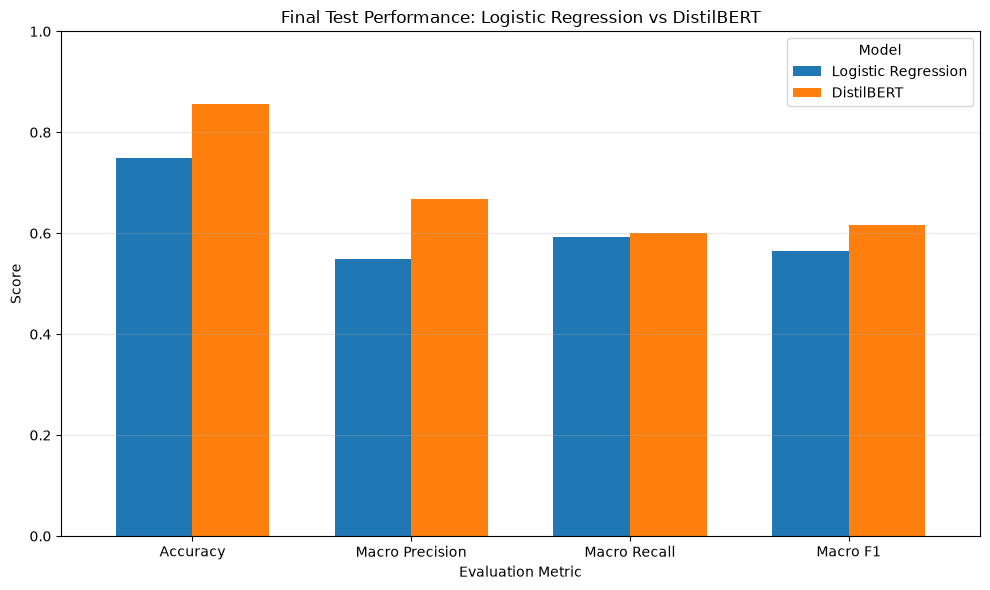

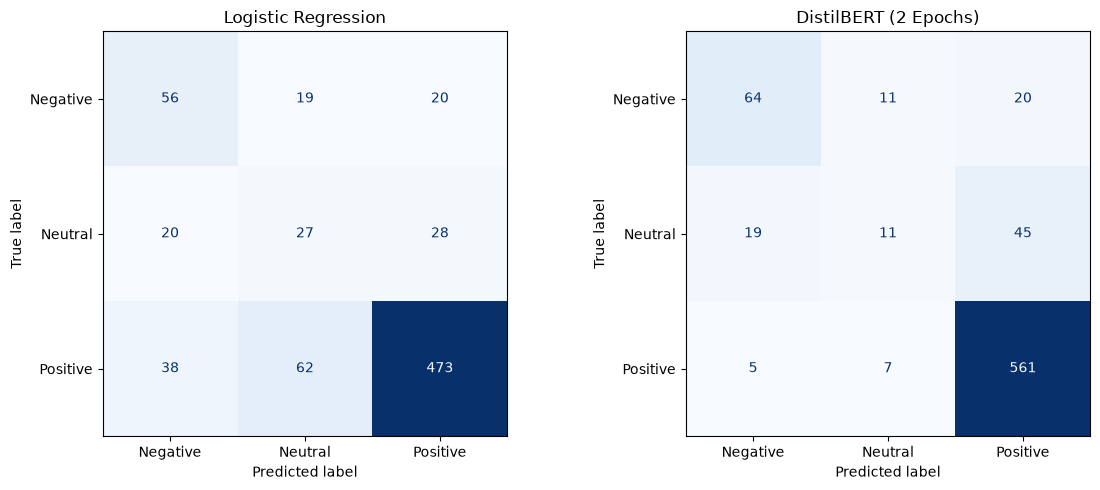


Files saved:
c:\Users\jyothi\sentiment-analysis-nlp\data\final_model_comparison.csv
c:\Users\jyothi\sentiment-analysis-nlp\data\final_model_comparison.png
c:\Users\jyothi\sentiment-analysis-nlp\data\final_confusion_matrices.png

Step 3.22 completed successfully!


In [3]:

# Step 3.22 - Final Model Comparison and Visualization

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Create comparison table
comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],
    "Logistic Regression": [
        lr_test_accuracy,
        lr_test_precision,
        lr_test_recall,
        lr_test_f1
    ],
    "DistilBERT": [
        bert_test_accuracy,
        bert_test_precision,
        bert_test_recall,
        bert_test_f1
    ]
})

print("Final Model Comparison")
print("----------------------")
print(comparison_df.round(4).to_string(index=False))

# 2. Save comparison results
results_path = project_path / "data" / "final_model_comparison.csv"

comparison_df.to_csv(results_path, index=False)

# 3. Create bar chart
plot_df = comparison_df.set_index("Metric")

ax = plot_df.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

plt.title("Final Test Performance: Logistic Regression vs DistilBERT")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

chart_path = project_path / "data" / "final_model_comparison.png"

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

# 4. Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

labels = ["Negative", "Neutral", "Positive"]

ConfusionMatrixDisplay(
    confusion_matrix=lr_test_cm,
    display_labels=labels
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay(
    confusion_matrix=bert_test_cm,
    display_labels=labels
).plot(
    ax=axes[1],
    cmap="Blues",
    colorbar=False
)

axes[1].set_title("DistilBERT (2 Epochs)")

plt.tight_layout()

cm_path = project_path / "data" / "final_confusion_matrices.png"

plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nFiles saved:")
print(results_path)
print(chart_path)
print(cm_path)

print("\nStep 3.22 completed successfully!")


In [4]:

# Step 3.23 - Error Analysis for Both Models

import pandas as pd
from sklearn.metrics import classification_report

# 1. Create a DataFrame containing predictions
error_analysis_df = pd.DataFrame({
    "review": test_df["text"].fillna("").astype(str).to_numpy(),
    "actual": y_test.to_numpy(),
    "logistic_prediction": lr_test_predictions,
    "distilbert_prediction": bert_predictions
})

# 2. Convert numerical labels into sentiment names
label_names = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

for column in [
    "actual",
    "logistic_prediction",
    "distilbert_prediction"
]:
    error_analysis_df[column] = (
        error_analysis_df[column].map(label_names)
    )

# 3. Identify incorrect predictions
error_analysis_df["logistic_error"] = (
    error_analysis_df["actual"]
    != error_analysis_df["logistic_prediction"]
)

error_analysis_df["distilbert_error"] = (
    error_analysis_df["actual"]
    != error_analysis_df["distilbert_prediction"]
)

# 4. Count errors
print("FINAL ERROR ANALYSIS")
print("--------------------")

print(
    "Logistic Regression errors:",
    error_analysis_df["logistic_error"].sum()
)

print(
    "DistilBERT errors:",
    error_analysis_df["distilbert_error"].sum()
)

# 5. Display Neutral review mistakes
neutral_errors = error_analysis_df[
    (error_analysis_df["actual"] == "Neutral")
    & (error_analysis_df["distilbert_error"])
]

print("\nDistilBERT Neutral Classification Errors:")
print("Total:", len(neutral_errors))

print(
    neutral_errors[
        ["review", "actual", "distilbert_prediction"]
    ].head(10).to_string(index=False, max_colwidth=100)
)

# 6. Find cases where Logistic Regression was correct
# but DistilBERT was incorrect
logistic_better = error_analysis_df[
    (~error_analysis_df["logistic_error"])
    & (error_analysis_df["distilbert_error"])
]

print("\nCases where Logistic Regression was correct")
print("but DistilBERT was incorrect:", len(logistic_better))

# 7. Find cases where DistilBERT was correct
# but Logistic Regression was incorrect
distilbert_better = error_analysis_df[
    (~error_analysis_df["distilbert_error"])
    & (error_analysis_df["logistic_error"])
]

print("\nCases where DistilBERT was correct")
print("but Logistic Regression was incorrect:", len(distilbert_better))

# 8. Save full error analysis
error_path = (
    project_path / "data" / "final_error_analysis.csv"
)

error_analysis_df.to_csv(
    error_path,
    index=False
)

print("\nError analysis saved to:", error_path)

print("\nStep 3.23 completed successfully!")


FINAL ERROR ANALYSIS
--------------------
Logistic Regression errors: 187
DistilBERT errors: 107

DistilBERT Neutral Classification Errors:
Total: 64
                                                                                              review  actual distilbert_prediction
they are not fragrance free though. As know, essential oils have fragrances to them and you can s... Neutral              Negative
I've always wanted to get into the art of doing my own acrylics so when I saw this drill set, I k... Neutral              Positive
The Removable/detachable Water Tank is not removable nor detachable. I studied the user manual an... Neutral              Negative
I was interested to try something new, but these did not work as well as the style I’d used previ... Neutral              Negative
I put it on using a stencil and liked the result. My hair is red brown. Sadly it didn't stay on a... Neutral              Negative
Doesnt last as long. But i guess its because this is more natura

In [5]:

# Step 3.24 - Analyze Errors by Sentiment Class

import pandas as pd

sentiments = ["Negative", "Neutral", "Positive"]

error_summary = []

for sentiment in sentiments:

    class_data = error_analysis_df[
        error_analysis_df["actual"] == sentiment
    ]

    total = len(class_data)

    lr_errors = int(
        class_data["logistic_error"].sum()
    )

    bert_errors = int(
        class_data["distilbert_error"].sum()
    )

    error_summary.append({
        "Sentiment": sentiment,
        "Total Reviews": total,
        "Logistic Errors": lr_errors,
        "DistilBERT Errors": bert_errors,
        "Logistic Error Rate (%)": round(
            lr_errors / total * 100, 2
        ),
        "DistilBERT Error Rate (%)": round(
            bert_errors / total * 100, 2
        )
    })

error_summary_df = pd.DataFrame(error_summary)

print("ERROR ANALYSIS BY SENTIMENT CLASS")
print("---------------------------------")

print(error_summary_df.to_string(index=False))

# Save results
summary_path = (
    project_path / "data" / "error_summary_by_class.csv"
)

error_summary_df.to_csv(
    summary_path,
    index=False
)

print("\nError summary saved to:", summary_path)

print("\nStep 3.24 completed successfully!")


ERROR ANALYSIS BY SENTIMENT CLASS
---------------------------------
Sentiment  Total Reviews  Logistic Errors  DistilBERT Errors  Logistic Error Rate (%)  DistilBERT Error Rate (%)
 Negative             95               39                 31                    41.05                      32.63
  Neutral             75               48                 64                    64.00                      85.33
 Positive            573              100                 12                    17.45                       2.09

Error summary saved to: c:\Users\jyothi\sentiment-analysis-nlp\data\error_summary_by_class.csv

Step 3.24 completed successfully!
